## Aquisition Timeline
Use the search_results.csv file to build an aquisition timeline for viewing

To be run in the `plotting` env

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
from datetime import datetime

# =============================================================================
# User settings
# =============================================================================

DATA_DIR = "/Volumes/T9_InSAR/2026-10-22_china/"
CSV_FILE = f"{DATA_DIR}search_results_nisar.csv"
KML_FILE = f"{DATA_DIR}search_results_nisar.kml"
# OUTPUT_FILE = f"{DATA_DIR}S1_acquisition_timeline.png"

EQ_TIME = datetime(2026, 10, 22, 14, 33, 40)
EQ_LABEL = "M5.7 Earthquake"
hypocenter = [93.780,32.380] #lon, lat

# =============================================================================
# Read and organize acquisition data
# =============================================================================

df = pd.read_csv(CSV_FILE)

# Convert acquisition timestamps to datetime objects
df["Start Time"] = pd.to_datetime(df["Start Time"])

# Sort chronologically
df = df.sort_values("Start Time")

# Unique path numbers (e.g., 64, 144)
tracks = sorted(df["Path Number"].unique())
# Check that for each path number, there is only one unique frame number
for track in tracks:
    unique_frames = df[df["Path Number"] == track]["Frame Number"].unique()
    if len(unique_frames) > 1:
        print(f"Multiple frame numbers found for path {track}: {unique_frames}")
        # Set tracks to be a list of tuples (path, frame) instead of just path numbers
        # tracks = [(row["Path Number"], row["Frame Number"]) for _, row in df.iterrows()]
# Assign vertical positions for plotting
levels = np.arange(len(tracks), 0, -1)
track_to_level = dict(zip(tracks, levels))

# Figure out which Platform(s) are being used.
# A single search can contain multiple sensor families (e.g. Sentinel-1 +
# NISAR). Each raw "Platform" string is mapped to a short family label so that
# e.g. Sentinel-1A / 1C / 1D all collapse to "S1".

# Mapping from raw platform-name prefix -> short family label.
# Add new sensors here as needed; anything unmatched falls back to its raw name.
SENSOR_LABELS = {
    "Sentinel-1": "S1",
    "SENTINEL-1": "S1",
    "NISAR": "NISAR",
    "ALOS-2": "ALOS-2",
    "ALOS2": "ALOS-2",
    "ALOS": "ALOS",
    "TerraSAR-X": "TSX",
    "TanDEM-X": "TDX",
    "RADARSAT-2": "RSAT-2",
    "RCM": "RCM",
    "COSMO-SkyMed": "CSK",
    "SAOCOM": "SAOCOM",
}


def resolve_sensor_label(platform_name):
    """Map a raw ASF 'Platform' string to a short sensor-family label."""
    name = str(platform_name).strip()
    for prefix, label in SENSOR_LABELS.items():
        if name.upper().startswith(prefix.upper()):
            return label
    # Unknown sensor: fall back to the raw name so it is still identifiable.
    return name


# Short family label per row (used for per-track legend entries later).
df["Sensor"] = df["Platform"].map(resolve_sensor_label)

# Distinct sensor families present in this search, in first-seen order.
sensor_families = list(dict.fromkeys(df["Sensor"].tolist()))

if len(sensor_families) == 1:
    # Single sensor family: use its short label for both titles and filenames.
    platform = sensor_families[0]
    platform_label = sensor_families[0]
else:
    # Multiple sensor families: use a safe 'combined' token for filenames and a
    # descriptive label (e.g. 'S1 + NISAR') for plot titles / legends.
    platform = "combined"
    platform_label = " + ".join(sensor_families)

print(f"Sensor families found: {sensor_families}")
print(f"Using platform token: {platform}  (label: {platform_label})")


Sensor families found: ['NISAR']
Using platform token: NISAR  (label: NISAR)


In [2]:
guesses=None

from guess_next_acquisition import guess_next_acquisitions
guesses = guess_next_acquisitions(df, repeat_days=12, n_future=2)
guesses


,Path Number,last_start,guess_n,guessed_start
0,91,2026-10-18 12:32:06+00:00,1,2026-10-30 12:32:06+00:00
1,91,2026-10-18 12:32:06+00:00,2,2026-11-11 12:32:06+00:00
2,112,2026-10-19 22:58:48+00:00,1,2026-10-31 22:58:48+00:00
3,112,2026-10-19 22:58:48+00:00,2,2026-11-12 22:58:48+00:00


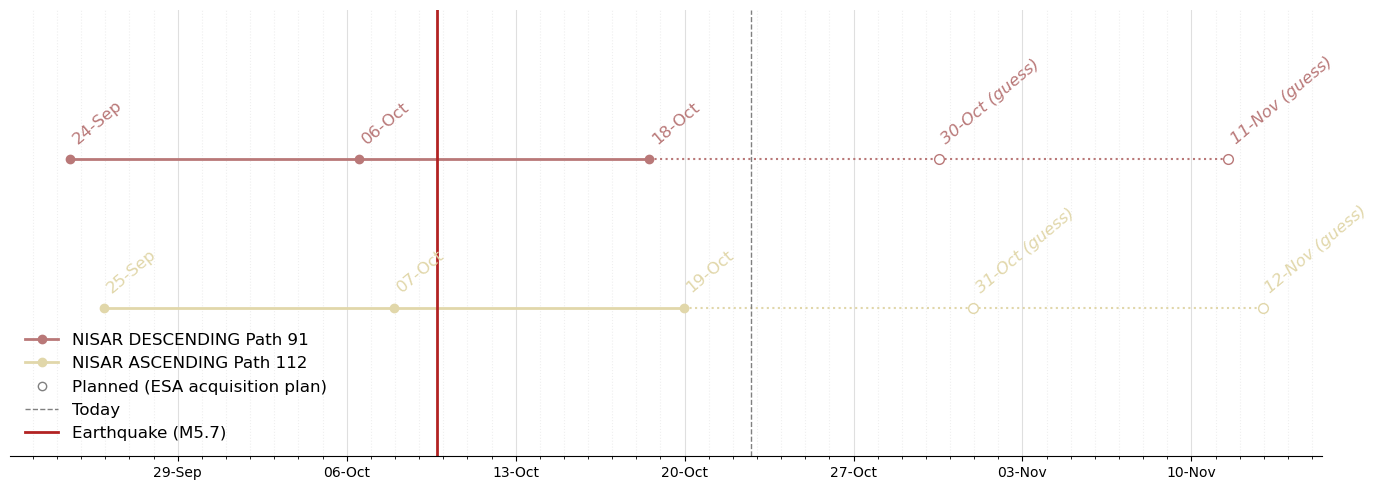

In [3]:
# =============================================================================
# Create figure
# =============================================================================

fig, ax = plt.subplots(figsize=(14, 5))

# Define color map
groups = list(df.groupby("Path Number"))
n_groups = len(groups)

# Divide the cmap into sections 1/n, where n is the number of paths 
cmap = plt.get_cmap("pink") # bone, pink
colors = cmap(
    np.linspace(
        1/(n_groups+1),
        n_groups/(n_groups+1),
        n_groups
    )
)

# =============================================================================
# Plot acquisitions by path
# =============================================================================
scene_color = {}
track_color = {}
for (track, subset), color in zip(
    df.groupby("Path Number"),
    colors
):

    subset = subset.sort_values("Start Time")

    for granule in subset["Granule Name"]:
        scene_color[granule] = color
    track_color[track] = color

    dates = subset["Start Time"]
    direction = subset["Ascending or Descending?"].iloc[0]
    # Per-track sensor label so a combined plot distinguishes sensors in the legend.
    track_sensor = subset["Sensor"].iloc[0]
    level = track_to_level[track]

    ax.plot(
        dates,
        np.full(len(dates), level),
        "o-",
        lw=2,
        ms=6,
        color=color,
        label=f"{track_sensor} {direction} Path {track}",
    )

    # Label each acquisition point
    for date in dates:
        ax.text(
            date,
            level + 0.08,
            date.strftime("%d-%b"),
            color=color,
            fontsize=12,
            rotation=40,
            ha="left",
            va="bottom",
        )

    # --- Guessed acquisitions (hollow markers, naive repeat-interval guess) ---
    if guesses is not None:
        fut = guesses[guesses["Path Number"] == track]
        if len(fut):
            fdates = fut["guessed_start"]
            # dotted connector from the last acquired scene to the first guessed one
            ax.plot([dates.iloc[-1], fdates.iloc[0]], [level, level], ":", lw=1.5, color=color)
            ax.plot(fdates, np.full(len(fdates), level), "o:", lw=1.5, ms=7,
                    mfc="white", mec=color, color=color)
            for date in fdates:
                ax.text(date, level + 0.08, f"{date:%d-%b} (guess)", color=color,
                        fontsize=12, rotation=40, ha="left", va="bottom", style="italic")

# Legend entries for planned acquisitions and today
ax.plot([], [], "o", mfc="white", mec="gray", color="gray", label="Planned (ESA acquisition plan)")
ax.axvline(pd.Timestamp.now(tz="UTC").tz_localize(None), color="gray", ls="--", lw=1, label="Today")
# =============================================================================
# Add earthquake marker
# =============================================================================

ax.axvline(
    EQ_TIME,
    color="firebrick",
    linewidth=2,
    label='Earthquake (M5.7)',
)

# =============================================================================
# Axis formatting
# =============================================================================

# Hide y-axis since levels are only used for separation
ax.set_ylim(0, len(tracks) + 1)
ax.yaxis.set_visible(False)

# Remove unnecessary frame elements
ax.spines["left"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(False)

# =============================================================================
# Constrain the x-axis to the acquisition dates in the CSV
# =============================================================================
# matplotlib would otherwise auto-scale to include the 'Today' line and the
# guessed future acquisitions, stretching the axis past the CSV date range.
# Limit to the span of df['Start Time'] with a small margin on each side.
data_start = df["Start Time"].min()
data_end = df["Start Time"].max()
pad = pd.Timedelta(days=2)
# ax.set_xlim(data_start - pad, data_end + pad)

# Weekly labels
# Weekly labels, thinned to ~10 labels if the timeline gets long
span_days = ax.get_xlim()[1] - ax.get_xlim()[0]
ax.xaxis.set_major_locator(mdates.WeekdayLocator(interval=max(1, int(span_days // 70))))

# Daily tick marks
ax.xaxis.set_minor_locator(mdates.DayLocator(interval=1))

# Label format: 14-Apr
ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%d-%b")
)

# Rotate labels vertically
plt.setp(
    ax.get_xticklabels(),
    rotation=0,
    ha="center"
)

# Grid lines
ax.grid(
    which="major",
    axis="x",
    linestyle="-",
    alpha=0.4,
)

ax.grid(
    which="minor",
    axis="x",
    linestyle=":",
    alpha=0.2,
)

# =============================================================================
# Finalize and save
# =============================================================================

ax.legend(frameon=False, fontsize=12)

plt.tight_layout()

plt.savefig(
    f"{DATA_DIR}{platform}_acquisition_timeline.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

# # Read CMT File and plot

# import sys
# sys.path.append("/Users/hyin/soft/shakemap-postprocess-tools/shakemap_utils/")
# sys.path.append("/Users/hyin/soft/shakemap-postprocess-tools/get-moment-tensor/")
# sys.path.append("/Users/hyin/soft/shakemap-postprocess-tools/plot_ruptquads/")
# from custom_utils import parse_mt, plot_mt
# from getMomentTensor import get_moment_tensor

# mt, eventid = parse_mt('/Volumes/T9_InSAR/2026-04-14_nevada/S1_D144/nn00914068_tensor.json')
# plot_mt(mt, eventid, outdir=DATA_DIR)



grdimage [WARNING]: Your grid y's or latitudes appear to be outside the map region and will be skipped.
grdimage [WARNING]: No grid or image inside plot domain


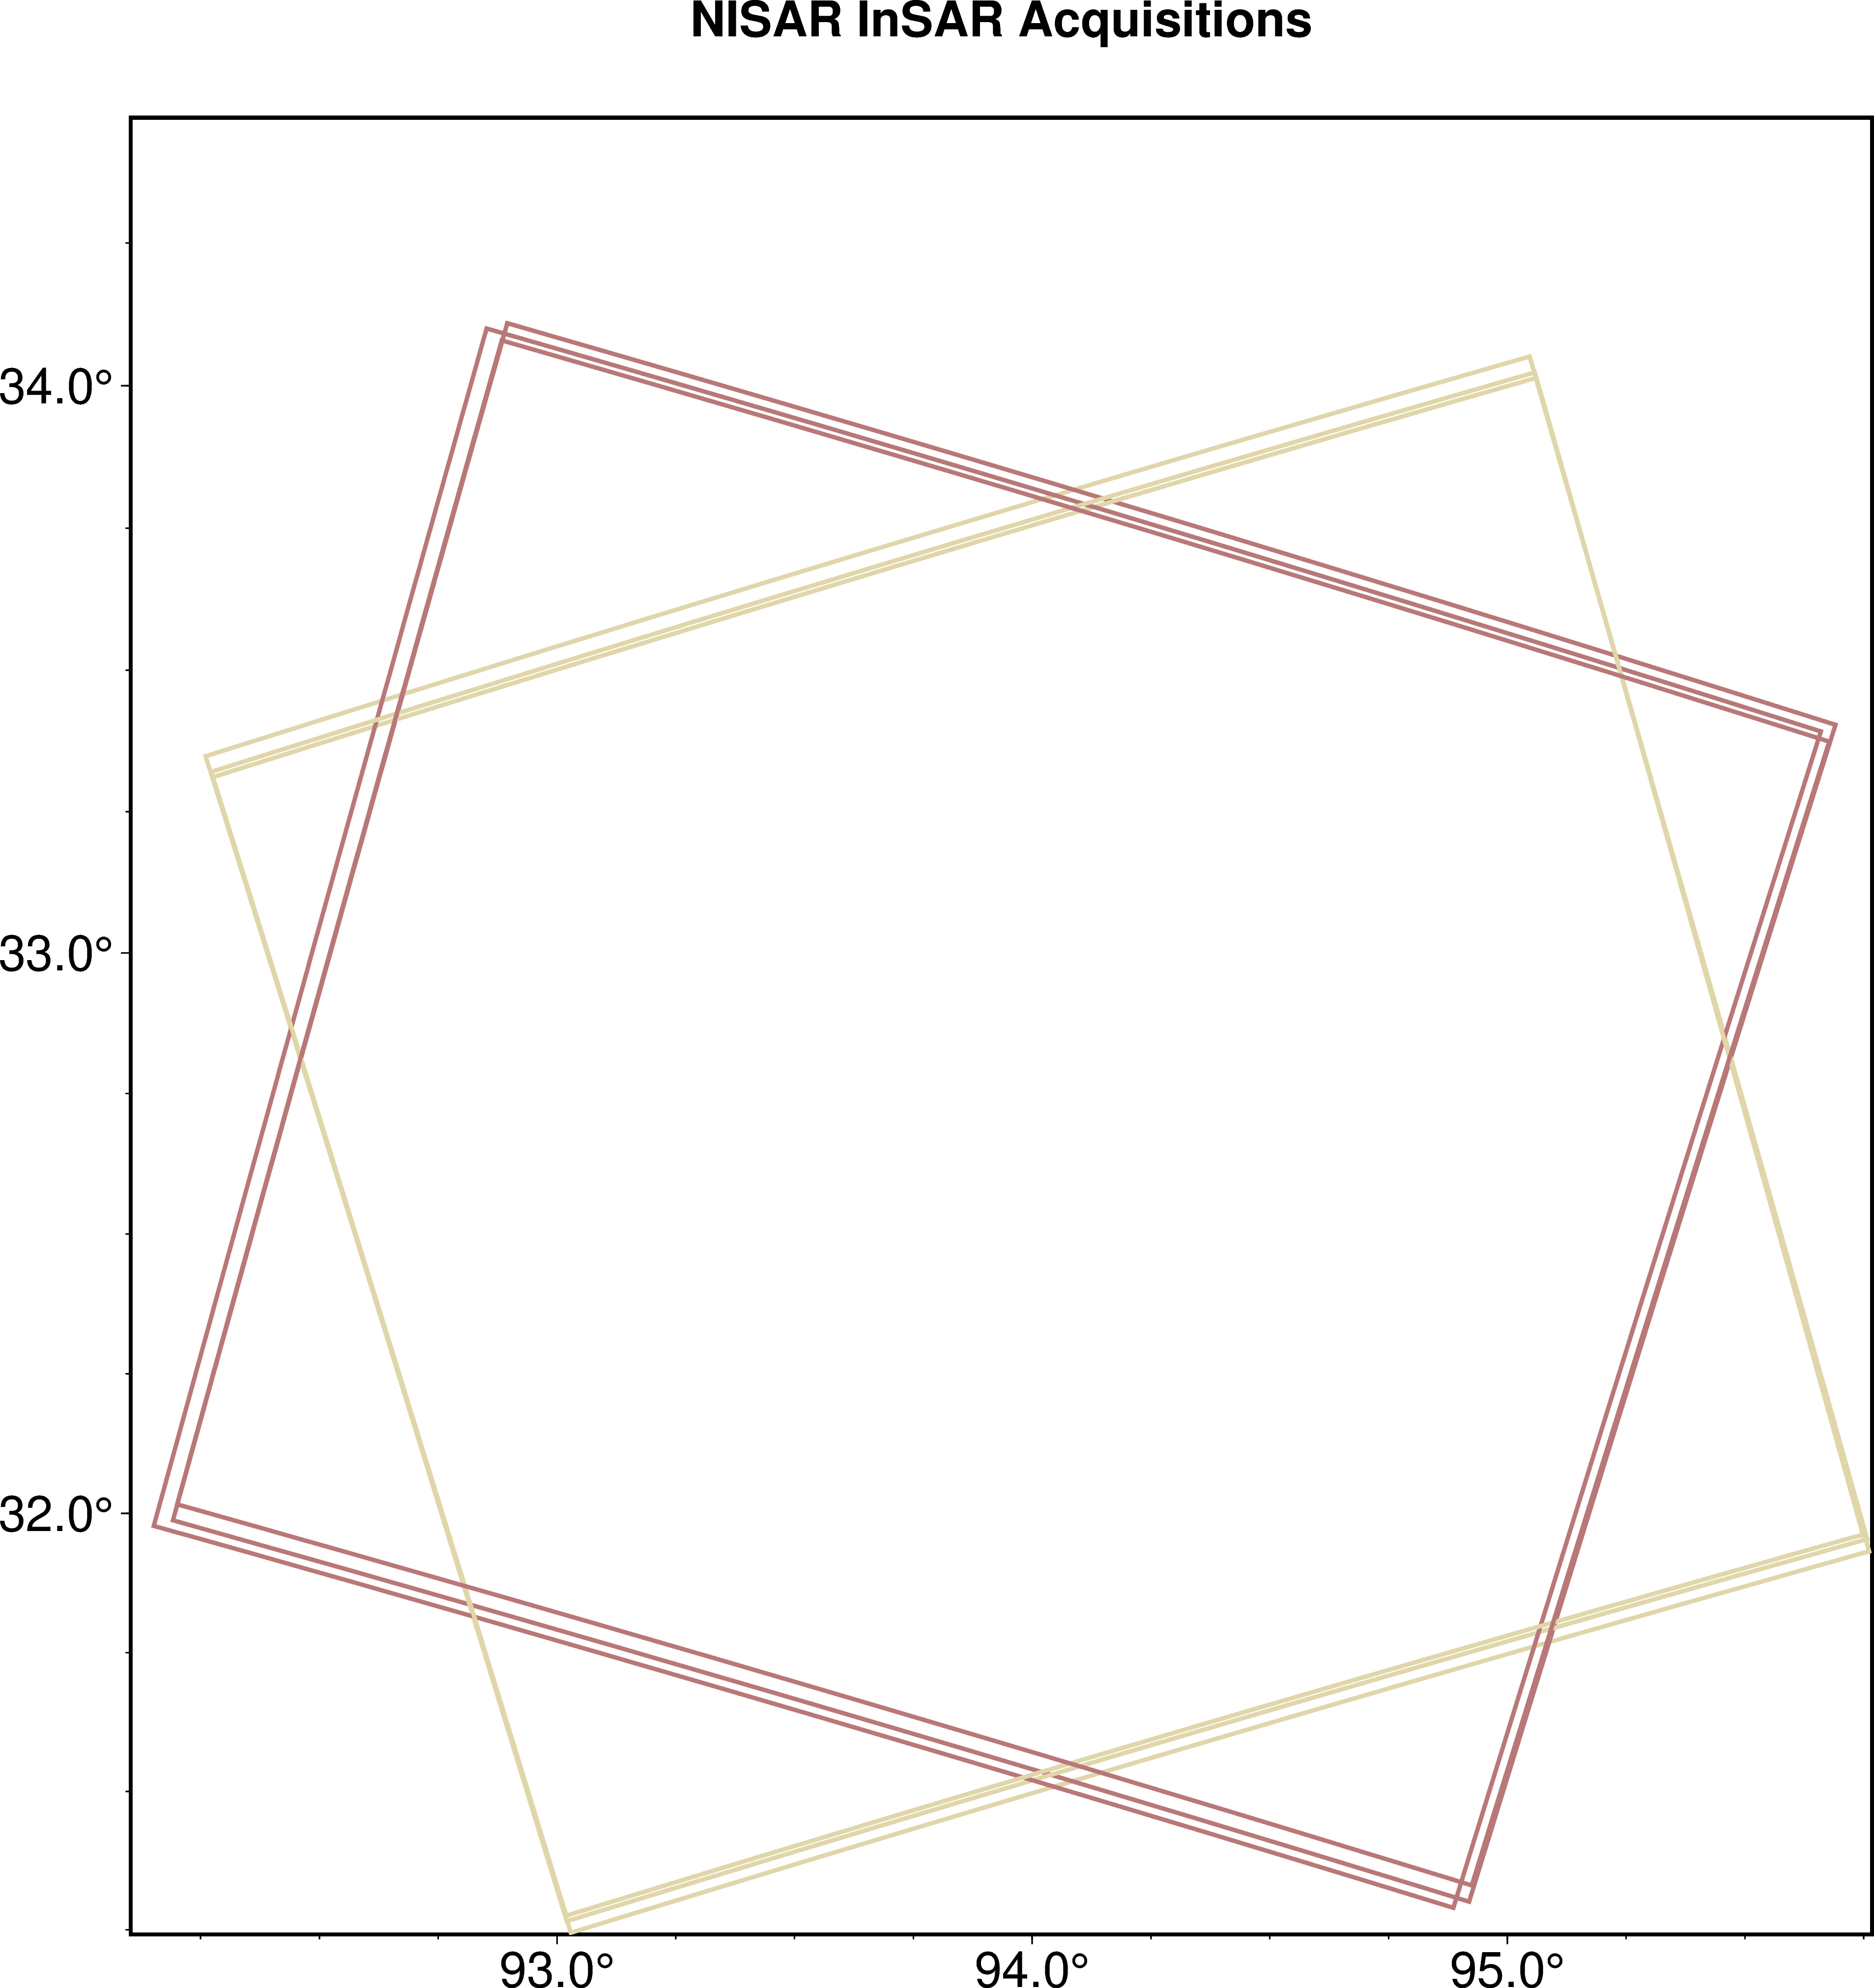

In [5]:
import pygmt

fig = pygmt.Figure()

# region = [-121, -116, 37, 41]

BL = [31.2416,92.1026] # Bottom Left (lat, lon), 
TR = [34.4687,95.7674] # Top Right (lat, lon)

region = [BL[1], TR[1], BL[0], TR[0]]  # [min_lon, max_lon, min_lat, max_lat]

# Set PyGMT universal configurations
pygmt.config(FORMAT_GEO_MAP="ddd.x", MAP_FRAME_TYPE="plain", FONT="24p")
projection = 'M0/0/30c'

fig.basemap(
    region=region,
    projection=projection,
    frame=True,
)

# Plot topography grd
pygmt.makecpt(cmap="gray", series=[-10, 0, 0.01])
fig.grdimage(
    grid='/Volumes/T9_InSAR/2026-10-02_australia/topo/dem_grad.grd',
    frame=[f"lSEt+t{platform_label} InSAR Acquisitions"],
    cmap=True,
    region=region,
)

fig.coast(
    shorelines="1p,black",
    borders="1/0.5p,black",
)


import geopandas as gpd

gdf = gpd.read_file(KML_FILE)   # 'Name' column = granule name, 'geometry' = the footprint

for _, row in gdf.iterrows():
    r, g, b = (np.array(scene_color[row["Name"]][:3]) * 255).astype(int)
    fig.plot(data=gpd.GeoSeries([row.geometry]), pen=f"2p,{r}/{g}/{b}")

# # Planned data takes (dashed, same color as their track)
# for _, row in future.iterrows():
#     r, g, b = (np.array(track_color[row["OrbitRelative"]][:3]) * 255).astype(int)
#     fig.plot(data=gpd.GeoSeries([row.geometry]), pen=f"1.5p,{r}/{g}/{b},dashed")

# Plot hypocenter
fig.plot(x=hypocenter[0], y = hypocenter[1], style="a0.9c", pen="2p,firebrick", fill="white", label="Hypocenter")

fig.show()

fig.savefig(
    f"{DATA_DIR}{platform}_acquisition_map.png",
    dpi=300,
)

plt.show()